# Water Conflicts in the Colorado River Basin


Data is collected from 9 recorded public meetings of water control boards and other offical organizations.  Data was also collected from newspaper articles from areas in the Colorado River Basin.

 Data collected ranges from January 1, 2005 to December 31, 2021.

The authors perceive the dataset to be useful for identifying and giving context for conflict and other water-related crises regarding water resource management in the Colorado River Basin.  This contect may be especially useful for USGS water availability reports.

The data was accessed on October 6, 2025 from Holloman et al. (2023).

Holloman, D.V., Hines, M.K., and Zoanni, D.K., 2023, Coded Water Conflict and Crisis Events in the Colorado River Basin, Derived from LexisNexis search 2005-2021: U.S. Geological Survey data release, (https://doi.org/10.5066/P9X6WR7J).

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/Colorado River Basin Water Conflict Table.csv')

## Preliminary Data Exploration

In [2]:
#Set pandas to display all columns in the data frame
pd.set_option('display.max_rows', None)

In [3]:
# Identify the types of data in each column and 
# how many observations have data for each
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 268 entries, 0 to 267
Data columns (total 48 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Event                                         268 non-null    int64  
 1   Search Source                                 268 non-null    object 
 2   Newspaper                                     268 non-null    object 
 3   Article Title                                 268 non-null    object 
 4   Duplicate                                     267 non-null    object 
 5   Report Date                                   267 non-null    object 
 6   Report Year                                   265 non-null    float64
 7   Event Date                                    248 non-null    object 
 8   Event Day                                     18 non-null     float64
 9   Event Month                                   212 non-null    flo

In [ ]:
# Identify the number of observations and number of columns in the data frame
df.shape

(268, 48)

There are a total of 268 observations in the dataset

In [ ]:
#Identify the names of the columns in the dataframe
df.columns

Index(['Event', 'Search Source', 'Newspaper', 'Article Title', 'Duplicate',
       'Report Date', 'Report Year', 'Event Date', 'Event Day', 'Event Month',
       'Event Year', 'Conflict Present', 'Crisis Present', 'Basin', 'HUC6',
       'HUC2', 'Place', 'County', 'County FIPS', 'State', 'State FIPS',
       'Urban or Rural', 'Issue Type', 'Event Summary', 'Stakeholders',
       'Intensity Value', 'Comments', 'Related Observation Themes',
       'Article Text Search - water quality',
       'Article Text Search - invasive species',
       'Article Text Search - conservation', 'Article Text Search - drought',
       'Article Text Search - flood',
       'Article Text Search - ground water depletion',
       'Article Text Search - depletion',
       'Article Text Search - infrastructure',
       'Article Text Search - fish passage',
       'Article Text Search - instream water rights',
       'Article Text Search - water rights',
       'Article Text Search - intergovernmental',
       '

In [4]:
#Identify the number of unique values are in each column
df.nunique()

Event                                           268
Search Source                                     6
Newspaper                                        45
Article Title                                   267
Duplicate                                         2
Report Date                                     235
Report Year                                      18
Event Date                                       52
Event Day                                        12
Event Month                                      12
Event Year                                       21
Conflict Present                                  2
Crisis Present                                    2
Basin                                            25
HUC6                                             22
HUC2                                              7
Place                                           135
County                                            3
County FIPS                                       3
State       

In [6]:
df.isna().sum()

Event                                             0
Search Source                                     0
Newspaper                                         0
Article Title                                     0
Duplicate                                         1
Report Date                                       1
Report Year                                       3
Event Date                                       20
Event Day                                       250
Event Month                                      56
Event Year                                       11
Conflict Present                                 16
Crisis Present                                   14
Basin                                            18
HUC6                                            158
HUC2                                             18
Place                                            14
County                                          260
County FIPS                                     260
State       

In [8]:
df['Issue Type'].value_counts()

Issue Type
Drought                                                                       66
Water rights more generally                                                   51
Conservation                                                                  43
Intergovernmental issues                                                      43
Infrastructure issues                                                         15
Water quality                                                                 10
Water transfers                                                                6
Instream water rights                                                          6
Flood                                                                          4
Intergovernmental issues: Water rights more generally                          2
Intergovernmental issues: Drought                                              1
Intergovernmental issues: Water transfers                                      1
Intergovernmental

Lots of different issues.  It looks like several have multiple types, so we'll need to do some string modification.


## Location Column Descriptions: State, Place, Conflict Present

In [10]:
df['Place'].unique()

array(['Durango, CO', 'Great Salt Lake',
       'Colorado River Indian Reservation',
       'Southern Ute Indian Reservation', 'State of Arizona',
       'Entire Colorado River Basin', 'All of Colorado River Basin',
       'Farmington, OH; Great Salt Lake', 'Navajo Nation; Window Rock AZ',
       'Bullhead City, AZ re: All of Colorado R. Basin', 'Phoenix, AZ',
       'Ute Tribe, Utah', 'Denver, CO; Shoshone power plant',
       'AZ, CO, NM, UT, Southern Ute Tribe, Ute Mountain tribe, Navajo Nation',
       'Colorado River Basin', 'Laughlin, AZ',
       'Colorado River Indian Reservation; Parker, AZ',
       'CA - Imperial Irrigation District', 'Flagstaff, AZ',
       'Glen Canyon Dam, Lake Powell, UT; AZ', 'Needles, CA',
       'AZ, NV, Mexico', 'CO, UT, WY, NM', 'Las Vegas, Southern CA; AZ',
       'Sacaton/Gila R. Indian Reservation', 'Boulder, CO', 'Lees Ferry',
       'AZ', 'Lake Powell (UT, AZ)', 'Glenwod Springs',
       'Multiple waterways in UT ', 'St. Michaels, AZ',
       'Th

`Place` is more of a description of varying lengths.  Typos are frequent.  There is some redundancy with `State`

In [13]:
df['State'].value_counts()

State
AZ                            66
CO                            34
UT                            27
NV                            10
CA                             7
NM                             6
AZ; CA                         4
AZ; UT                         3
AZ; CA; CO; NV; NM; UT; WY     3
AZ; NV                         2
NV; AZ                         2
CO; AZ                         2
CO; UT; WY; NM                 2
AZ; NM                         1
CA; NV; AZ                     1
WY; UT; CO                     1
UT; CO; WY                     1
CO; WY                         1
AZ; CA; NV                     1
UT; AZ                         1
AZ; CO; NM; UT                 1
OH; UT                         1
TX                             1
Name: count, dtype: int64

Multiple state codes are listed of some entries, without a fixed order

In [11]:
df['Conflict Present'].value_counts()

Conflict Present
Y    145
N    107
Name: count, dtype: int64

## 5. String Accessor for `pandas.Series`

In [16]:
# Create an example series resembling your data
s = pd.Series(['California: Nevada', 'Arizona', np.nan, 'Nevada; Utah'])

#Use s.str.split to separate the character chains into lists,
# specify the break point
s.str.split(';')

# use `.explode()`` to separate the list into rows
s.str.split(';').explode()

0    California: Nevada
1               Arizona
2                   NaN
3                Nevada
3                  Utah
dtype: object

## Examine State Codes

In [36]:
df.loc[df['State'].notna() , 'State'].value_counts(dropna =False)

State
AZ                            66
CO                            34
UT                            27
NV                            10
CA                             7
NM                             6
AZ; CA                         4
AZ; UT                         3
AZ; CA; CO; NV; NM; UT; WY     3
AZ; NV                         2
NV; AZ                         2
CO; AZ                         2
CO; UT; WY; NM                 2
AZ; NM                         1
CA; NV; AZ                     1
WY; UT; CO                     1
UT; CO; WY                     1
CO; WY                         1
AZ; CA; NV                     1
UT; AZ                         1
AZ; CO; NM; UT                 1
OH; UT                         1
TX                             1
Name: count, dtype: int64

## 7. Brainstorm

1) Filter to entries where `Conflict Present` is True

2) Use `str.split` to separate the states in each entry

3) Use .`explode()` to move each state into a separate entry

4) Use `.strip()` to remove extra spaces

5) Use `.unique()` to obtain a list of the unique values in the column

## 8. Exploratory wrangling

In [33]:
#Filter to states where there are conflicts
conflicts = df.loc[df['Conflict Present'] == 'Y']

#Separate the list of states
conflict_states = conflicts['State'].str.split(';').explode().str.strip()

## 9. Find unique codes

In [27]:
conflict_states_unique = (df.loc[df['Conflict Present'] == 'Y', 'State']
    .str.split(';')
    .explode()
    .str.strip()
    .unique())

conflict_states_unique

array(['CO', nan, 'AZ', 'OH', 'UT',
       'CA', 'NV', 'WY', 'NM'],
      dtype=object)

## 10. Visualize & discuss

<Axes: title={'center': 'Water conflicts in the Colorado River Basin by State (2005 - 2021)'}, xlabel='Number of conflicts', ylabel='State'>

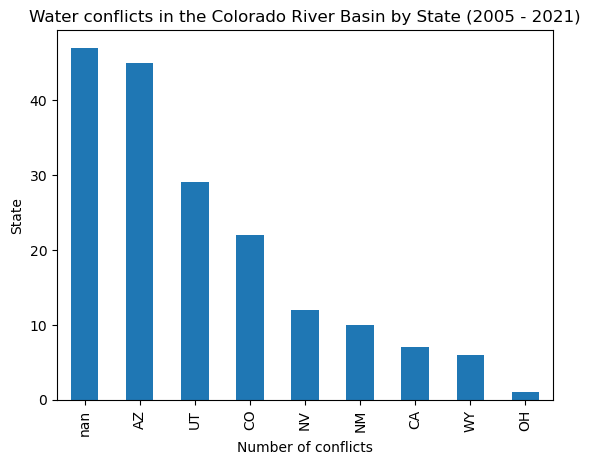

In [40]:
conflict_states_count = (df.loc[df['Conflict Present'] == 'Y', 'State']
    .str.split(';')
    .explode()
    .str.strip()
    .value_counts(dropna = False)
    )

conflict_states_count.plot(
    kind = 'bar',
    xlabel = 'Number of conflicts',
    ylabel = 'State',
    title = 'Water conflicts in the Colorado River Basin by State (2005 - 2021)'
)